# AMR Training — Reduced ALL_FEATURES (Top 10,000 SNPs + Genes + K-mers)
**Input:** `{antibiotic}_ALL_FEATURES_REDUCED.csv` — one per antibiotic  
**Models:** XGBoost, RandomForest, ExtraTrees, GradientBoosting  
**Validation:** 6-fold Stratified Cross-Validation  
**Output:** best model per antibiotic saved as `.pkl`

In [1]:
# ── CELL 1: Install & Version Check ───────────────────────────────────────
!pip install xgboost imbalanced-learn scikit-learn -q

import sklearn
import xgboost as xgb
import pandas as pd
import numpy as np

print('── Version Check ──────────────────────────────')
print(f'  scikit-learn : {sklearn.__version__}')
print(f'  xgboost      : {xgb.__version__}')
print(f'  pandas       : {pd.__version__}')
print(f'  numpy        : {np.__version__}')
print('───────────────────────────────────────────────')

# Warn if sklearn < 1.0 (affects some API calls)
from packaging import version
if version.parse(sklearn.__version__) < version.parse('1.0'):
    print('⚠ sklearn < 1.0 detected — consider upgrading: pip install -U scikit-learn')
else:
    print('✓ sklearn version OK')

── Version Check ──────────────────────────────
  scikit-learn : 1.4.2
  xgboost      : 3.1.3
  pandas       : 2.2.2
  numpy        : 1.26.4
───────────────────────────────────────────────
✓ sklearn version OK


In [2]:
# ── CELL 2: All Imports ────────────────────────────────────────────────────
import os
import pickle
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             classification_report, confusion_matrix)
from sklearn.ensemble import (RandomForestClassifier,
                              ExtraTreesClassifier,
                              GradientBoostingClassifier)
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('✓ Imports complete')

✓ Imports complete


In [3]:
# ── CELL 3: Configuration ──────────────────────────────────────────────────
# ⚠ DATA_DIR = folder where you saved the merged ALL_FEATURES_REDUCED files
# ⚠ MODEL_DIR = where trained models (.pkl) will be saved

DATA_DIR  = 'C:/Users/USER/Downloads/E_coli/final_merged_outputs'
MODEL_DIR = 'C:/Users/USER/Downloads/E_coli/models'

os.makedirs(MODEL_DIR, exist_ok=True)

# File suffix for the new merged datasets with reduced SNPs
# After your merge step these should be named e.g. amoxicillin_ALL_FEATURES_REDUCED.csv
DATASET_SUFFIX = 'ALL_FEATURES'

# ⚠ Label column — adjust if yours differs
ANTIBIOTICS = {
    'amoxicillin': 'Phenotype_Label',
    'coxime'     : 'Phenotype_Label',
    'doxy'       : 'Phenotype_Label',
    'levo'       : 'Phenotype_Label',
    'nali'       : 'Phenotype_Label',
    'norflo'     : 'Phenotype_Label',
    'strep'      : 'Phenotype_Label',
    'tetra'      : 'Phenotype_Label',
}

ANTIBIOTIC_FULL = {
    'amoxicillin': 'Amoxicillin/Clavulanic Acid',
    'coxime'     : 'Cefuroxime',
    'doxy'       : 'Doxycycline',
    'levo'       : 'Levofloxacin',
    'nali'       : 'Nalidixic Acid',
    'norflo'     : 'Norfloxacin',
    'strep'      : 'Streptomycin',
    'tetra'      : 'Tetracycline',
}

CONFIG = {
    'n_folds'      : 6,
    'random_state' : RANDOM_STATE,
    'top_n_features': 30,
}

print('Configuration:')
for k, v in CONFIG.items():
    print(f'  {k}: {v}')
print(f'\nData directory : {DATA_DIR}')
print(f'Model directory: {MODEL_DIR}')
print(f'Dataset suffix : {DATASET_SUFFIX}')

Configuration:
  n_folds: 6
  random_state: 42
  top_n_features: 30

Data directory : C:/Users/USER/Downloads/E_coli/final_merged_outputs
Model directory: C:/Users/USER/Downloads/E_coli/models
Dataset suffix : ALL_FEATURES


In [4]:
# ── CELL 4: Helper Functions ───────────────────────────────────────────────

def load_data(filepath, label_col):
    """Load CSV, auto-detect label if needed, return X, y."""
    df = pd.read_csv(filepath)
    df['Genome_ID'] = df['Genome_ID'].astype(str)

    if label_col not in df.columns:
        candidates = [c for c in df.columns if 'phenotype' in c.lower() or 'label' in c.lower()]
        if candidates:
            label_col = candidates[0]
            print(f'  ℹ Auto-detected label: {label_col}')
        else:
            raise KeyError(f'Label column not found. Available: {df.columns.tolist()[:10]}')

    X = df.drop(columns=['Genome_ID', label_col])
    y = df[label_col]

    assert y.isin([0, 1]).all(), f'Labels must be 0/1. Found: {y.unique()}'

    print(f'  ✓ {len(X)} samples × {X.shape[1]:,} features')
    print(f'    Susceptible (0): {(y==0).sum()}  |  Resistant (1): {(y==1).sum()}')
    return X, y, label_col


def get_models(scale_pos_weight):
    """Define all four models."""
    return {
        'XGBoost': XGBClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            subsample=0.8, colsample_bytree=0.5,
            reg_alpha=1, reg_lambda=1,
            random_state=CONFIG['random_state'],
            eval_metric='logloss', verbosity=0
        ),
        'RandomForest': RandomForestClassifier(
            n_estimators=100, max_depth=10,
            min_samples_split=5, min_samples_leaf=2,
            class_weight='balanced', n_jobs=-1,
            random_state=CONFIG['random_state']
        ),
        'ExtraTrees': ExtraTreesClassifier(
            n_estimators=100, max_depth=10,
            min_samples_split=5, min_samples_leaf=2,
            class_weight='balanced', n_jobs=-1,
            random_state=CONFIG['random_state']
        ),
        'GradientBoosting': GradientBoostingClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.1,
            random_state=CONFIG['random_state']
        ),
    }


def run_cv(X, y):
    """6-fold stratified CV — returns per-fold results."""
    scale_pos_weight = (y == 0).sum() / max((y == 1).sum(), 1)
    models = get_models(scale_pos_weight)
    skf    = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True,
                             random_state=CONFIG['random_state'])
    results = {name: [] for name in models}

    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        X_tr, X_te = X.iloc[tr], X.iloc[te]
        y_tr, y_te = y.iloc[tr], y.iloc[te]

        for name, model in models.items():
            model.fit(X_tr, y_tr)
            y_pred = model.predict(X_te)
            results[name].append({
                'fold'     : fold,
                'accuracy' : accuracy_score(y_te, y_pred),
                'precision': precision_score(y_te, y_pred, zero_division=0),
                'recall'   : recall_score(y_te, y_pred, zero_division=0),
                'f1'       : f1_score(y_te, y_pred, zero_division=0),
            })
        print(f'    Fold {fold}/{CONFIG["n_folds"]} done')

    return results


def summarize(results):
    """Mean ± std per model."""
    out = {}
    for model, folds in results.items():
        df = pd.DataFrame(folds)
        out[model] = {m: (df[m].mean(), df[m].std())
                      for m in ['accuracy', 'precision', 'recall', 'f1']}
    return out


print('✓ Helper functions ready')

✓ Helper functions ready


In [5]:
# ── CELL 5: Training Loop — All 8 Antibiotics ─────────────────────────────

all_results  = {}   # all_results[ab_prefix] = {summary, n_features, ...}
all_X        = {}   # store X for best-model retraining in Cell 7
all_y        = {}   # store y for best-model retraining in Cell 7
all_label_cols = {} # store detected label col per antibiotic

for ab_prefix, label_col in ANTIBIOTICS.items():
    ab_full  = ANTIBIOTIC_FULL[ab_prefix]
    filepath = os.path.join(DATA_DIR, f'{ab_prefix}_{DATASET_SUFFIX}.csv')

    print(f'\n{"#"*70}')
    print(f'  {ab_full}')
    print(f'  File: {os.path.basename(filepath)}')
    print(f'{"#"*70}')

    if not os.path.exists(filepath):
        print(f'  ⚠ File not found — skipping')
        all_results[ab_prefix] = None
        continue

    try:
        X, y, detected_label = load_data(filepath, label_col)
    except Exception as e:
        print(f'  ⚠ Load error: {e}')
        all_results[ab_prefix] = None
        continue

    all_X[ab_prefix]          = X
    all_y[ab_prefix]          = y
    all_label_cols[ab_prefix] = detected_label

    print(f'  Running 6-fold CV...')
    cv_results = run_cv(X, y)
    summary    = summarize(cv_results)

    all_results[ab_prefix] = {
        'summary'   : summary,
        'n_features': X.shape[1],
        'n_samples' : len(X),
        'class_dist': {0: int((y==0).sum()), 1: int((y==1).sum())},
    }

    print(' Results (mean ± std across 6 folds):')
    print(f'  {"Model":<22} {"Accuracy":>10} {"Precision":>11} {"Recall":>9} {"F1":>9}')
    print(f'  {"-"*65}')
    for model, metrics in summary.items():
        print(f'  {model:<22}  '
              f'{metrics["accuracy"][0]:.3f}±{metrics["accuracy"][1]:.3f}  '
              f'{metrics["precision"][0]:.3f}±{metrics["precision"][1]:.3f}  '
              f'{metrics["recall"][0]:.3f}±{metrics["recall"][1]:.3f}  '
              f'{metrics["f1"][0]:.3f}±{metrics["f1"][1]:.3f}')

print('\n\n✓ All training complete!')


######################################################################
  Amoxicillin/Clavulanic Acid
  File: amoxicillin_ALL_FEATURES.csv
######################################################################
  ✓ 571 samples × 42,342 features
    Susceptible (0): 319  |  Resistant (1): 252
  Running 6-fold CV...
    Fold 1/6 done
    Fold 2/6 done
    Fold 3/6 done
    Fold 4/6 done
    Fold 5/6 done
    Fold 6/6 done
 Results (mean ± std across 6 folds):
  Model                    Accuracy   Precision    Recall        F1
  -----------------------------------------------------------------
  XGBoost                 0.890±0.013  0.874±0.017  0.877±0.046  0.875±0.018
  RandomForest            0.858±0.034  0.831±0.043  0.853±0.051  0.841±0.038
  ExtraTrees              0.869±0.030  0.850±0.033  0.853±0.055  0.851±0.036
  GradientBoosting        0.895±0.024  0.894±0.021  0.865±0.056  0.878±0.032

######################################################################
  Cefuroxime
  File: co

In [6]:
# ── CELL 6: Results Table & Best Model Selection ──────────────────────────

rows = []
for ab_prefix, result in all_results.items():
    if result is None:
        continue
    for model, metrics in result['summary'].items():
        rows.append({
            'Antibiotic'  : ANTIBIOTIC_FULL[ab_prefix],
            'ab_prefix'   : ab_prefix,
            'Model'       : model,
            'N_Features'  : result['n_features'],
            'N_Samples'   : result['n_samples'],
            'Susceptible' : result['class_dist'][0],
            'Resistant'   : result['class_dist'][1],
            'Accuracy'    : round(metrics['accuracy'][0],  4),
            'Accuracy_Std': round(metrics['accuracy'][1],  4),
            'Precision'   : round(metrics['precision'][0], 4),
            'Recall'      : round(metrics['recall'][0],    4),
            'F1'          : round(metrics['f1'][0],        4),
            'F1_Std'      : round(metrics['f1'][1],        4),
        })

results_df = pd.DataFrame(rows)

# Save full table
out_csv = os.path.join(DATA_DIR, 'training_results_snps.csv')
results_df.to_csv(out_csv, index=False)
print(f'✓ Full results saved: {out_csv}\n')

# Best model per antibiotic — highest F1
best_df = (
    results_df
    .sort_values('F1', ascending=False)
    .groupby('Antibiotic')
    .first()
    .reset_index()
)[['Antibiotic', 'ab_prefix', 'Model', 'F1', 'F1_Std', 'Accuracy', 'Recall', 'Precision', 'N_Features']]

print('='*95)
print('BEST MODEL PER ANTIBIOTIC  (ranked by F1-score)')
print('='*95)
print(best_df[['Antibiotic', 'Model', 'F1', 'F1_Std', 'Accuracy', 'Recall', 'N_Features']].to_string(index=False))

best_csv = os.path.join(DATA_DIR, 'best_model_per_antibiotic.csv')
best_df.to_csv(best_csv, index=False)
print(f'\n✓ Best model table saved: {best_csv}')

✓ Full results saved: C:/Users/USER/Downloads/E_coli/final_merged_outputs\training_results_snps.csv

BEST MODEL PER ANTIBIOTIC  (ranked by F1-score)
                 Antibiotic            Model     F1  F1_Std  Accuracy  Recall  N_Features
Amoxicillin/Clavulanic Acid GradientBoosting 0.8784  0.0316    0.8949  0.8651       42342
                 Cefuroxime GradientBoosting 0.9607  0.0252    0.9720  0.9386       42342
                Doxycycline       ExtraTrees 0.9604  0.0157    0.9458  0.9424       42342
               Levofloxacin          XGBoost 0.9680  0.0196    0.9790  0.9625       42342
             Nalidixic Acid          XGBoost 0.9425  0.0220    0.9562  0.9234       42342
                Norfloxacin          XGBoost 0.9488  0.0176    0.9580  0.9447       42342
               Streptomycin GradientBoosting 0.9486  0.0234    0.9334  0.9363       42342
               Tetracycline       ExtraTrees 0.9805  0.0100    0.9755  0.9777       42342

✓ Best model table saved: C:/Users/USER/

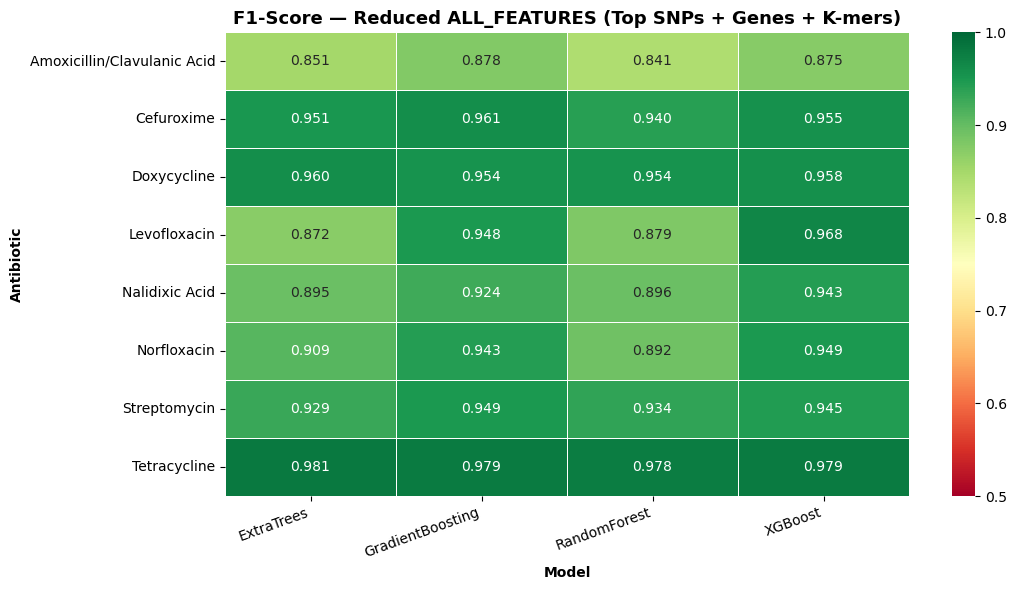

✓ Saved: f1_heatmap.png


In [7]:
# ── CELL 7: Heatmap — F1 by Antibiotic × Model ────────────────────────────

pivot = results_df.pivot_table(index='Antibiotic', columns='Model', values='F1')

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(
    pivot,
    annot=True, fmt='.3f', cmap='RdYlGn',
    vmin=0.5, vmax=1.0,
    linewidths=0.5, ax=ax
)
ax.set_title('F1-Score — Reduced ALL_FEATURES (Top SNPs + Genes + K-mers)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Model', fontweight='bold')
ax.set_ylabel('Antibiotic', fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'f1_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: f1_heatmap.png')

In [8]:
# ── CELL 8: Retrain Best Model on Full Data & Save ─────────────────────────
# For each antibiotic: take the best model from Cell 6,
# retrain it on ALL samples (no train/test split),
# save as a .pkl file.

saved_models = {}

for _, row in best_df.iterrows():
    ab_prefix  = row['ab_prefix']
    ab_full    = row['Antibiotic']
    best_model_name = row['Model']

    if ab_prefix not in all_X:
        print(f'⚠ {ab_full} — data not loaded, skipping')
        continue

    X = all_X[ab_prefix]
    y = all_y[ab_prefix]

    print(f'\n── {ab_full} → {best_model_name} ────────────────────────')
    print(f'   Retraining on {len(X)} samples × {X.shape[1]:,} features...')

    scale_pos_weight = (y == 0).sum() / max((y == 1).sum(), 1)
    final_model = get_models(scale_pos_weight)[best_model_name]
    final_model.fit(X, y)

    # Save model
    model_filename = f'{ab_prefix}_ecoli_model.pkl'
    model_path     = os.path.join(MODEL_DIR, model_filename)
    with open(model_path, 'wb') as f:
        pickle.dump({
            'model'        : final_model,
            'model_name'   : best_model_name,
            'antibiotic'   : ab_full,
            'features'     : X.columns.tolist(),
            'n_features'   : X.shape[1],
            'n_samples'    : len(X),
            'label_col'    : all_label_cols[ab_prefix],
            'cv_f1'        : row['F1'],
            'cv_accuracy'  : row['Accuracy'],
            'sklearn_ver'  : sklearn.__version__,
            'xgboost_ver'  : xgb.__version__,
        }, f)

    print(f'   ✓ Saved: {model_path}')
    print(f'   CV F1={row["F1"]:.3f}  |  CV Accuracy={row["Accuracy"]:.3f}')
    saved_models[ab_prefix] = model_path

print(f'\n{"="*70}')
print(f'✓ {len(saved_models)}/8 models saved to: {MODEL_DIR}')
print(f'{"="*70}')


── Amoxicillin/Clavulanic Acid → GradientBoosting ────────────────────────
   Retraining on 571 samples × 42,342 features...
   ✓ Saved: C:/Users/USER/Downloads/E_coli/models\amoxicillin_ecoli_model.pkl
   CV F1=0.878  |  CV Accuracy=0.895

── Cefuroxime → GradientBoosting ────────────────────────
   Retraining on 571 samples × 42,342 features...
   ✓ Saved: C:/Users/USER/Downloads/E_coli/models\coxime_ecoli_model.pkl
   CV F1=0.961  |  CV Accuracy=0.972

── Doxycycline → ExtraTrees ────────────────────────
   Retraining on 571 samples × 42,342 features...
   ✓ Saved: C:/Users/USER/Downloads/E_coli/models\doxy_ecoli_model.pkl
   CV F1=0.960  |  CV Accuracy=0.946

── Levofloxacin → XGBoost ────────────────────────
   Retraining on 571 samples × 42,342 features...
   ✓ Saved: C:/Users/USER/Downloads/E_coli/models\levo_ecoli_model.pkl
   CV F1=0.968  |  CV Accuracy=0.979

── Nalidixic Acid → XGBoost ────────────────────────
   Retraining on 571 samples × 42,342 features...
   ✓ Saved: C:

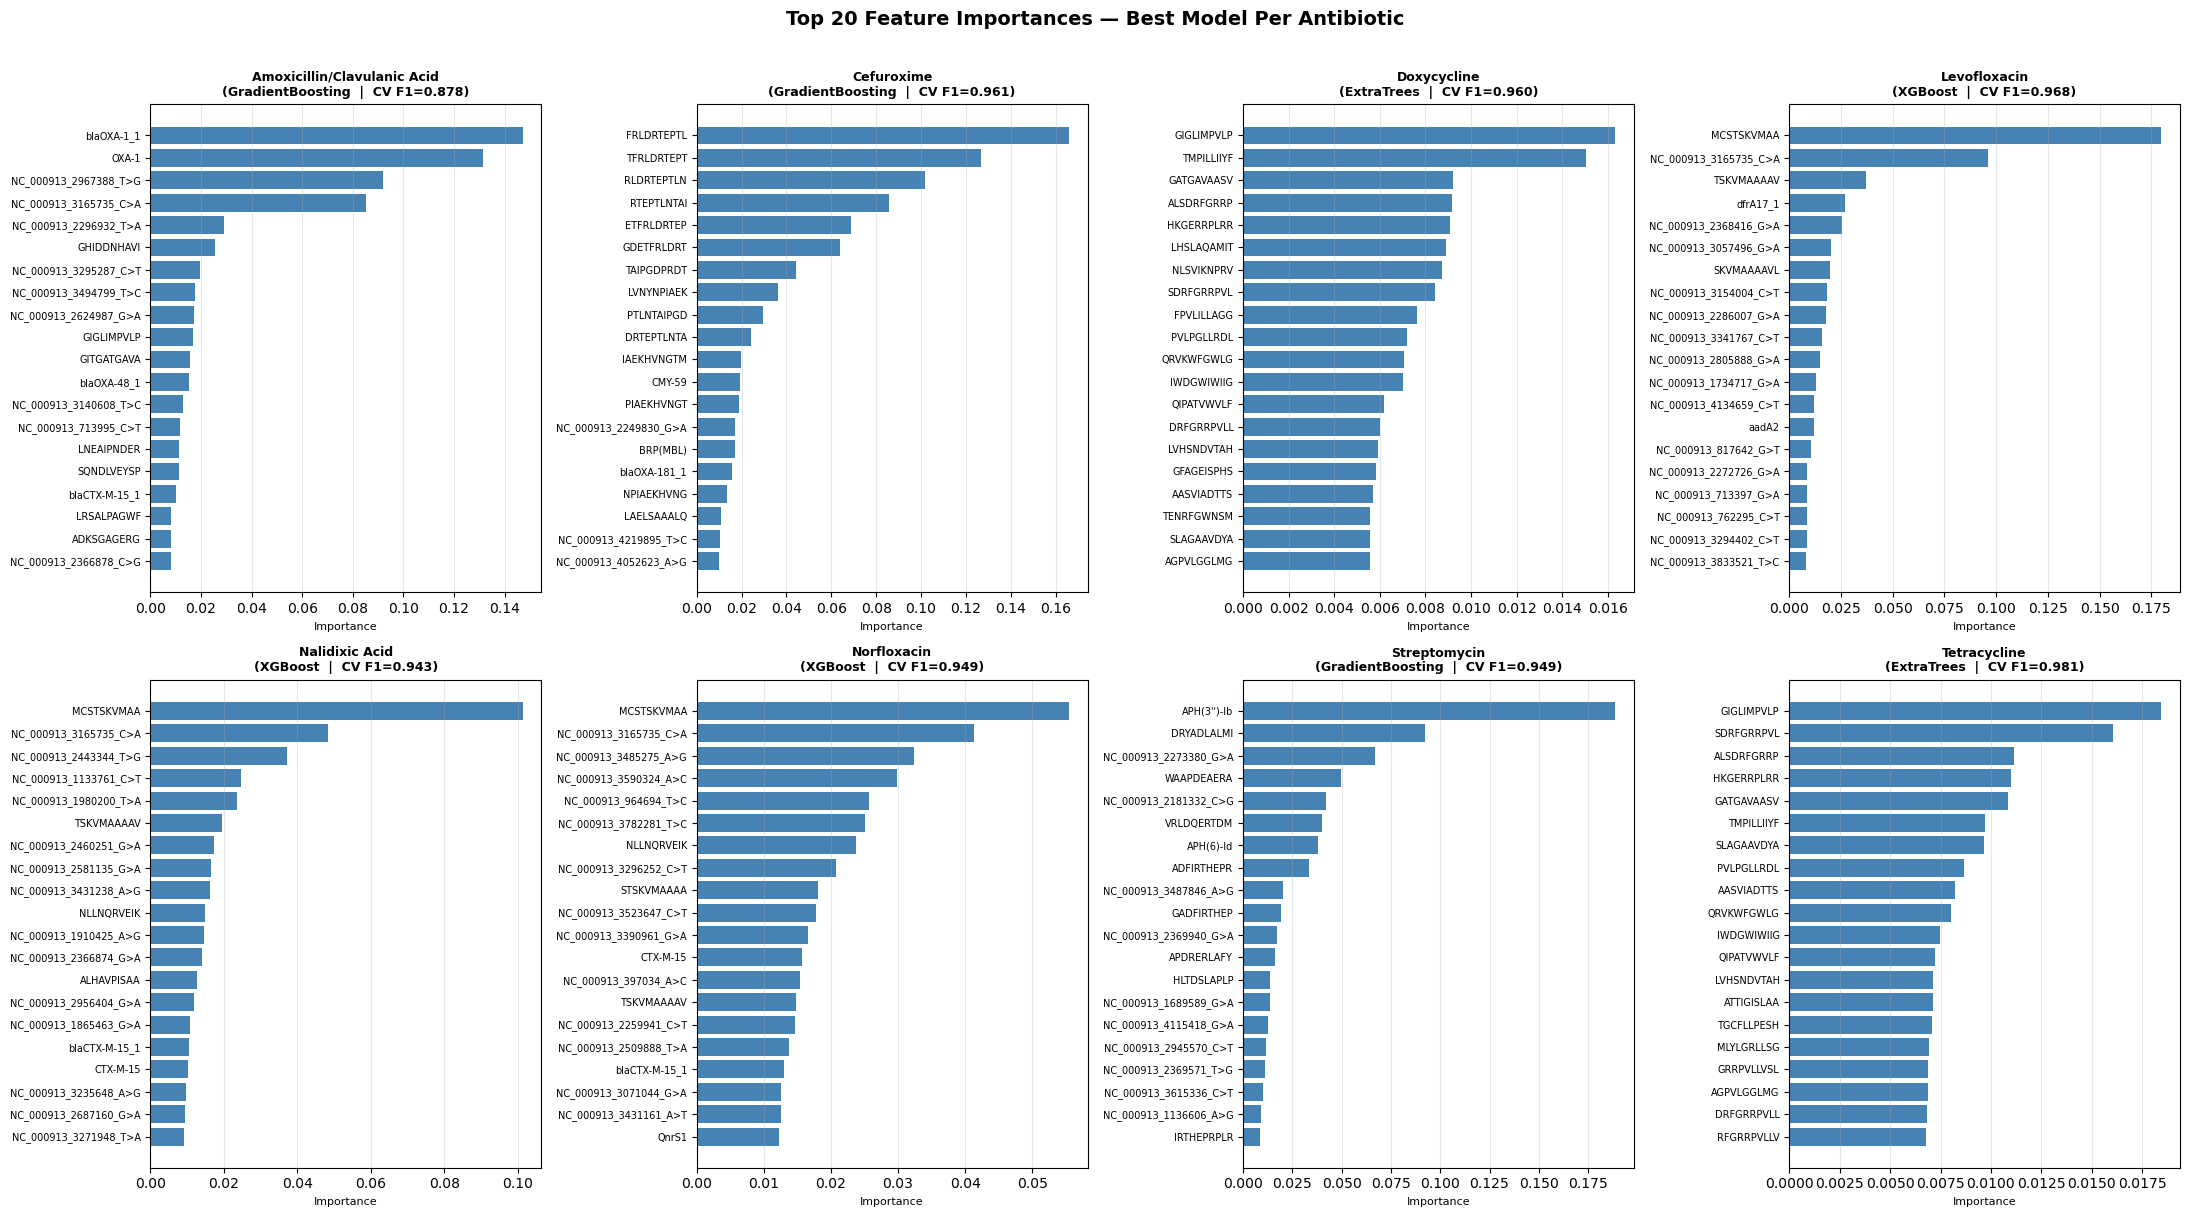

✓ Saved: feature_importance_reduced.png


In [9]:
# ── CELL 9: Feature Importance — Best Model Per Antibiotic ────────────────
# Shows top 20 features for each saved model

n_ab  = len(saved_models)
ncols = 4
nrows = (n_ab + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(22, nrows * 6))
axes = axes.flatten()

for idx, (ab_prefix, model_path) in enumerate(saved_models.items()):
    with open(model_path, 'rb') as f:
        saved = pickle.load(f)

    model        = saved['model']
    feature_list = saved['features']
    ab_full      = saved['antibiotic']
    model_name   = saved['model_name']

    ax = axes[idx]

    if not hasattr(model, 'feature_importances_'):
        ax.text(0.5, 0.5, 'No feature_importances_\navailable', ha='center')
        ax.set_title(ab_full)
        continue

    imp = pd.Series(model.feature_importances_, index=feature_list)
    top = imp.nlargest(20).sort_values()

    ax.barh(top.index, top.values, color='steelblue')
    ax.set_title(f'{ab_full}\n({model_name}  |  CV F1={saved["cv_f1"]:.3f})',
                 fontweight='bold', fontsize=9)
    ax.set_xlabel('Importance', fontsize=8)
    ax.tick_params(axis='y', labelsize=7)
    ax.grid(axis='x', alpha=0.3)

for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Top 20 Feature Importances — Best Model Per Antibiotic',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'feature_importance.png'), dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: feature_importance_reduced.png')

In [10]:
# ── CELL 10: How to Load a Saved Model ────────────────────────────────────
# Reference cell — shows how to reload and use a saved model

import pickle

# Example: load the tetracycline model
example_path = os.path.join(MODEL_DIR, 'tetra_extratrees_final.pkl')  # update model name if needed

if os.path.exists(example_path):
    with open(example_path, 'rb') as f:
        loaded = pickle.load(f)

    print('── Loaded model metadata ───────────────────────')
    print(f'  Antibiotic   : {loaded["antibiotic"]}')
    print(f'  Model        : {loaded["model_name"]}')
    print(f'  N features   : {loaded["n_features"]:,}')
    print(f'  Trained on   : {loaded["n_samples"]} samples')
    print(f'  CV F1        : {loaded["cv_f1"]:.3f}')
    print(f'  CV Accuracy  : {loaded["cv_accuracy"]:.3f}')
    print(f'  sklearn ver  : {loaded["sklearn_ver"]}')
    print(f'  xgboost ver  : {loaded["xgboost_ver"]}')
    print(f'\n  Model object : {loaded["model"]}')

    # To predict on new data:
    # new_df = pd.read_csv('new_isolates.csv')
    # X_new  = new_df[loaded['features']]   # align columns exactly
    # preds  = loaded['model'].predict(X_new)
else:
    print(f'⚠ Example file not found: {example_path}')
    print(f'  Update the path to one of your saved .pkl files')

⚠ Example file not found: C:/Users/USER/Downloads/E_coli/models\tetra_extratrees_final.pkl
  Update the path to one of your saved .pkl files


In [11]:
# ── CELL 11: Final Summary ─────────────────────────────────────────────────

print('='*80)
print('FINAL SUMMARY')
print('='*80)
print(f'  Antibiotics trained : {len(saved_models)}/8')
print(f'  Feature set         : Top  SNPs + Genes + K-mers')
print(f'  Validation          : 6-fold stratified CV')
print()
print(f'  {"Antibiotic":<32} {"Best Model":<20} {"F1":>6}  {"Accuracy":>9}')
print(f'  {"-"*75}')
for _, row in best_df.iterrows():
    if row['ab_prefix'] in saved_models:
        print(f'  {row["Antibiotic"]:<32} {row["Model"]:<20} {row["F1"]:>6.3f}  {row["Accuracy"]:>9.3f}')

print()
print('Files saved:')
print(' training_results_snps.csv')
print(' best_model_per_antibiotic.csv')
print(' f1_heatmap.png')
print( 'feature_importance.png')
for ab_prefix, path in saved_models.items():
    print(f'  ✓ {os.path.basename(path)}')

FINAL SUMMARY
  Antibiotics trained : 8/8
  Feature set         : Top  SNPs + Genes + K-mers
  Validation          : 6-fold stratified CV

  Antibiotic                       Best Model               F1   Accuracy
  ---------------------------------------------------------------------------
  Amoxicillin/Clavulanic Acid      GradientBoosting      0.878      0.895
  Cefuroxime                       GradientBoosting      0.961      0.972
  Doxycycline                      ExtraTrees            0.960      0.946
  Levofloxacin                     XGBoost               0.968      0.979
  Nalidixic Acid                   XGBoost               0.943      0.956
  Norfloxacin                      XGBoost               0.949      0.958
  Streptomycin                     GradientBoosting      0.949      0.933
  Tetracycline                     ExtraTrees            0.981      0.976

Files saved:
 training_results_snps.csv
 best_model_per_antibiotic.csv
 f1_heatmap.png
feature_importance.png
  ✓ am